# Tugas Lab 1 - Klasterisasi Data Nasabah Kartu Kredit dengan Agglomerative Clustering
* Menggunakan dataset `CC_Customer_Dataset.csv`
* Membuat model klasterisasi Agglomerative Clustering dengan seluruh variabel yang dapat digunakan.
* Menampilkan scatterplot berdasarkan dua variabel: `Avg_Credit_Limit` dan `Total_credit_card`.
* Menentukan nilai *silhouette score* dan DBI dari model.


## Langkah 1 - Import Library
Import library yang dibutuhkan.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
import scipy.cluster.hierarchy as sch
from sklearn.metrics import silhouette_score, davies_bouldin_score


## Langkah 2 - Load Dataset
Load dataset `CC_Customer_Dataset.csv` dan lakukan inspeksi struktur data.


In [2]:
df = pd.read_csv('Dataset/CC_Customer_Dataset.csv')
df.head()


,Sl_No,Customer Key,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
0,1,87073,100000,2,1,1,0
1,2,38414,50000,3,0,10,9
2,3,17341,50000,7,1,3,4
3,4,40496,30000,5,1,1,4
4,5,47437,100000,6,0,12,3


In [3]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 660 entries, 0 to 659
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   Sl_No                660 non-null    int64
 1   Customer Key         660 non-null    int64
 2   Avg_Credit_Limit     660 non-null    int64
 3   Total_Credit_Cards   660 non-null    int64
 4   Total_visits_bank    660 non-null    int64
 5   Total_visits_online  660 non-null    int64
 6   Total_calls_made     660 non-null    int64
dtypes: int64(7)
memory usage: 36.2 KB


## Langkah 3 - Seleksi Fitur dan Standardisasi
Menggunakan seluruh variabel prediktor perilaku nasabah (mengecualikan kolom ID `Sl_No` dan `Customer Key`), kemudian melakukan penskalaan fitur dengan `StandardScaler`.


In [4]:
features = ['Avg_Credit_Limit', 'Total_Credit_Cards', 'Total_visits_bank', 'Total_visits_online', 'Total_calls_made']
X = df[features].values

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


## Langkah 4 - Visualisasi Dendrogram
Membuat visualisasi dendrogram dengan metode Ward untuk mempermudah penentuan jumlah cluster yang optimal.


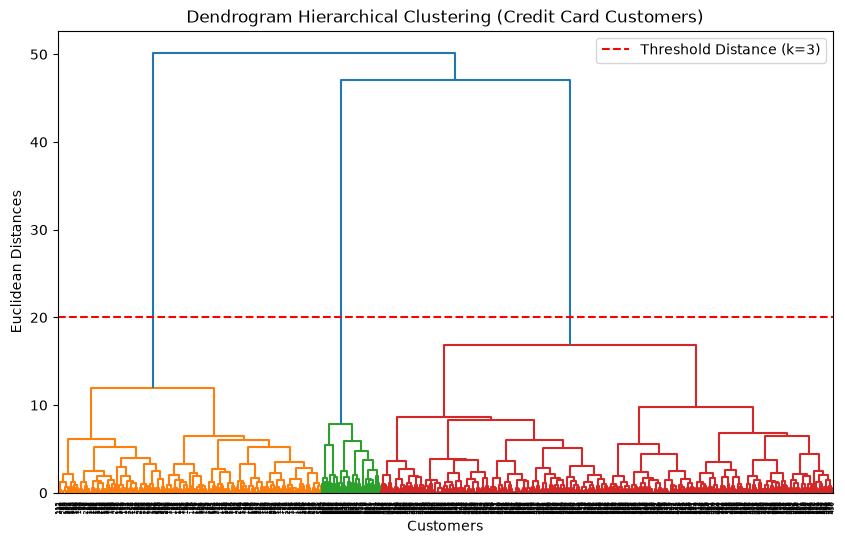

In [5]:
plt.figure(figsize=(10, 6))
dendrogram = sch.dendrogram(sch.linkage(X_scaled, method='ward'))
plt.title('Dendrogram Hierarchical Clustering (Credit Card Customers)')
plt.xlabel('Customers')
plt.ylabel('Euclidean Distances')
plt.axhline(y=20, color='r', linestyle='--', label='Threshold Distance (k=3)')
plt.legend()
plt.show()


## Langkah 5 - Inisialisasi dan Pelatihan Model Agglomerative Clustering
Berdasarkan dendrogram, jumlah cluster yang optimal adalah 3. Kita latih model Agglomerative Clustering dengan `n_clusters=3`.


In [6]:
hc = AgglomerativeClustering(n_clusters=3, metric='euclidean', linkage='ward')
y_hc = hc.fit_predict(X_scaled)
df['Cluster'] = y_hc


## Langkah 6 - Visualisasi Cluster
Visualisasi hasil klasterisasi menggunakan scatterplot pada variabel `Avg_Credit_Limit` dan `Total_Credit_Cards`.


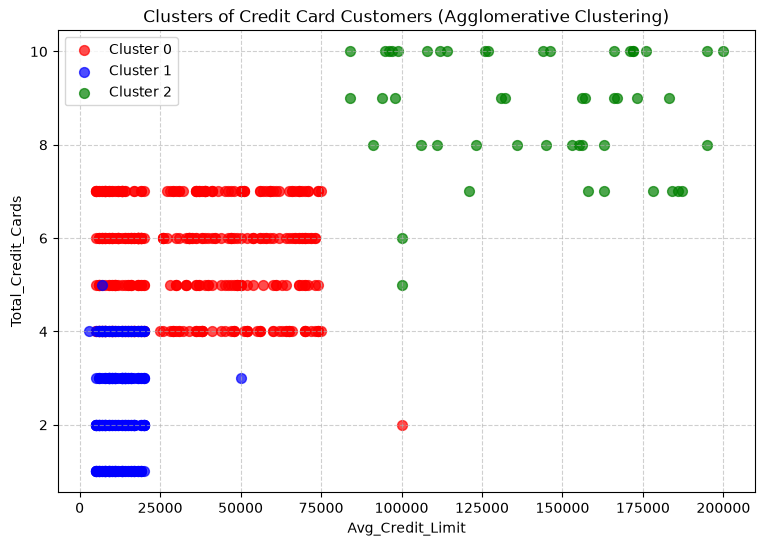

In [7]:
plt.figure(figsize=(9, 6))
colors = ['red', 'blue', 'green']
labels = ['Cluster 0', 'Cluster 1', 'Cluster 2']

for c in range(3):
    plt.scatter(
        df[df['Cluster'] == c]['Avg_Credit_Limit'],
        df[df['Cluster'] == c]['Total_Credit_Cards'],
        s=50, c=colors[c], label=labels[c], alpha=0.7
    )

plt.title('Clusters of Credit Card Customers (Agglomerative Clustering)')
plt.xlabel('Avg_Credit_Limit')
plt.ylabel('Total_Credit_Cards')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()


## Langkah 7 - Evaluasi Model (Silhouette Score dan Davies-Bouldin Index)
Menghitung nilai Silhouette Score dan Davies-Bouldin Index dari model klasterisasi.


In [8]:
sil_score = silhouette_score(X_scaled, y_hc)
dbi_score = davies_bouldin_score(X_scaled, y_hc)

print(f"Silhouette Score      : {sil_score:.4f}")
print(f"Davies-Bouldin Index  : {dbi_score:.4f}")


Silhouette Score      : 0.5148
Davies-Bouldin Index  : 0.6810
